In [33]:
import shutil
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

In [34]:
DATA_DIR = Path("../data")
TEST_DIR = DATA_DIR / "test"

OOF_DIR = Path("../oof")

ANALYSIS_DIR = Path("../analysis")

BASE_WRONG = ANALYSIS_DIR / "wrong_images"

ALL_DIR = BASE_WRONG / "all_wrong"
ONE_DIR = BASE_WRONG / "one_correct"
TWO_DIR = BASE_WRONG / "two_correct"

for folder in [ALL_DIR, ONE_DIR, TWO_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

In [35]:
for folder in [ALL_DIR, ONE_DIR, TWO_DIR]:

    for f in folder.glob("*"):
        f.unlink()

In [36]:
convnext = np.load(OOF_DIR / "convnext_test.npy")
swin = np.load(OOF_DIR / "swin_test.npy")
siglip = np.load(OOF_DIR / "siglip_test.npy")

In [37]:
manual = pd.read_csv("manual_label.csv")
submission = pd.read_csv("submission.csv")

In [38]:
weights = {
    "convnext":0.60,
    "swin":0.10,
    "siglip":0.30
}

final_probs = (
    weights["convnext"]*convnext +
    weights["swin"]*swin +
    weights["siglip"]*siglip
)

In [39]:
submission["manual"] = manual["label"].values

submission["convnext"] = convnext.argmax(1)
submission["swin"] = swin.argmax(1)
submission["siglip"] = siglip.argmax(1)
submission["ensemble"] = final_probs.argmax(1)

In [40]:
wrong_df = submission[
    submission["ensemble"] != submission["manual"]
].copy()

wrong_df.reset_index(drop=True, inplace=True)

In [41]:
cases = []

for _, row in wrong_df.iterrows():

    gt = row.manual

    correct = (
        int(row.convnext == gt) +
        int(row.swin == gt) +
        int(row.siglip == gt)
    )

    if correct == 0:
        cases.append("All Models Wrong")

    elif correct == 1:
        cases.append("One Model Correct")

    elif correct == 2:
        cases.append("Two Models Correct")

    else:
        cases.append("All Models Correct")

wrong_df["case"] = cases

In [42]:
wrong_df["filename"] = wrong_df["id"].astype(str) + ".jpg"

In [43]:
wrong_df.to_csv(
    ANALYSIS_DIR / "wrong_cases.csv",
    index=False
)

print(wrong_df["case"].value_counts())

case
All Models Wrong      41
One Model Correct     15
Two Models Correct     5
Name: count, dtype: int64


In [44]:
for _, row in wrong_df.iterrows():

    src = TEST_DIR / row.filename

    if row.case == "All Models Wrong":
        dst = ALL_DIR / row.filename

    elif row.case == "One Model Correct":
        dst = ONE_DIR / row.filename

    elif row.case == "Two Models Correct":
        dst = TWO_DIR / row.filename

    else:
        continue

    shutil.copy2(src, dst)

In [45]:
LABELS = {
    0:"Recycleable",
    1:"Electronic",
    2:"Organic"
}

In [46]:
i = 0

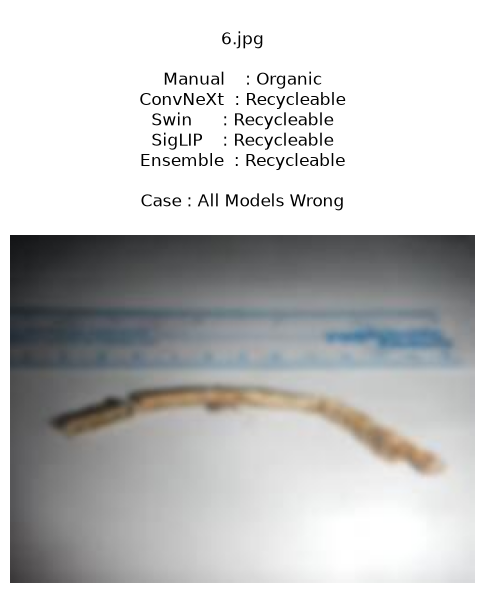

In [47]:
row = wrong_df.iloc[i]

if row.case == "All Models Wrong":
    folder = ALL_DIR

elif row.case == "One Model Correct":
    folder = ONE_DIR

else:
    folder = TWO_DIR

img = cv2.imread(str(folder / row.filename))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))

plt.imshow(img)

plt.axis("off")

plt.title(f"""
{row.filename}

Manual    : {LABELS[int(row.manual)]}
ConvNeXt  : {LABELS[int(row.convnext)]}
Swin      : {LABELS[int(row.swin)]}
SigLIP    : {LABELS[int(row.siglip)]}
Ensemble  : {LABELS[int(row.ensemble)]}

Case : {row.case}
""")

plt.show()

In [48]:
correct = (
    (wrong_df["convnext"] == wrong_df["manual"]).astype(int)
    + (wrong_df["swin"] == wrong_df["manual"]).astype(int)
    + (wrong_df["siglip"] == wrong_df["manual"]).astype(int)
)

correct.value_counts().sort_index()

0    41
1    15
2     5
Name: count, dtype: int64